# Problem 5: Choosing the proposal variance

Repeat Problem 4a with the same Gaussian target, mean $\mu=(2,2)$ and covariance
$$V=\begin{pmatrix}2&1.2\\1.2&2\end{pmatrix}.$$
We vary the proposal **variance per coordinate** $v$:
$$z'=z+\epsilon,\qquad \epsilon\sim\mathcal N_2(0,vI).$$
NumPy's normal generator takes a standard deviation, so the proposal scale is $\sqrt v$, not $v$. The symmetric proposal still cancels from the acceptance ratio for every $v$.

We compare $v=10^{-6},\ 10^{-1},\ 1,\ 10^{12}$. Each run starts at $(0,0)$, uses seed 42 and 50,000 transitions, retains rejected states, and discards no burn-in. A tiny variance is included to make the small-step failure visible. The two marginal histograms and scatter plots match the layout of Problem 4; traces show movement over time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

mean = np.array([2.0, 2.0])
V = np.array([[2.0, 1.2], [1.2, 2.0]])
V_inv = np.linalg.inv(V)

def log_p(z):
    d = z - mean
    return -0.5 * d @ V_inv @ d

def sample(variance):
    rng = np.random.default_rng(42)
    z = np.zeros(2)
    chain = np.empty((50_000, 2))
    accepted = 0
    for i in range(len(chain)):
        proposal = z + rng.normal(scale=np.sqrt(variance), size=2)
        if np.log(rng.random()) < min(0.0, log_p(proposal) - log_p(z)):
            z = proposal
            accepted += 1
        chain[i] = z
    return chain, accepted / len(chain)

variances = [1e-6, 0.1, 1.0, 1e12]
runs = [(v, *sample(v)) for v in variances]
for v, chain, acceptance in runs:
    print(f"v={v:g}: acceptance={acceptance:.4f}, mean={chain.mean(0).round(3)}, "
          f"variance={chain.var(0).round(3)}")

v=1e-06: acceptance=0.9996, mean=[-0.023 -0.091], variance=[0.005 0.005]
v=0.1: acceptance=0.8631, mean=[1.962 1.936], variance=[2.163 2.067]
v=1: acceptance=0.6077, mean=[1.982 1.963], variance=[2.015 1.985]
v=1e+12: acceptance=0.0000, mean=[0. 0.], variance=[0. 0.]


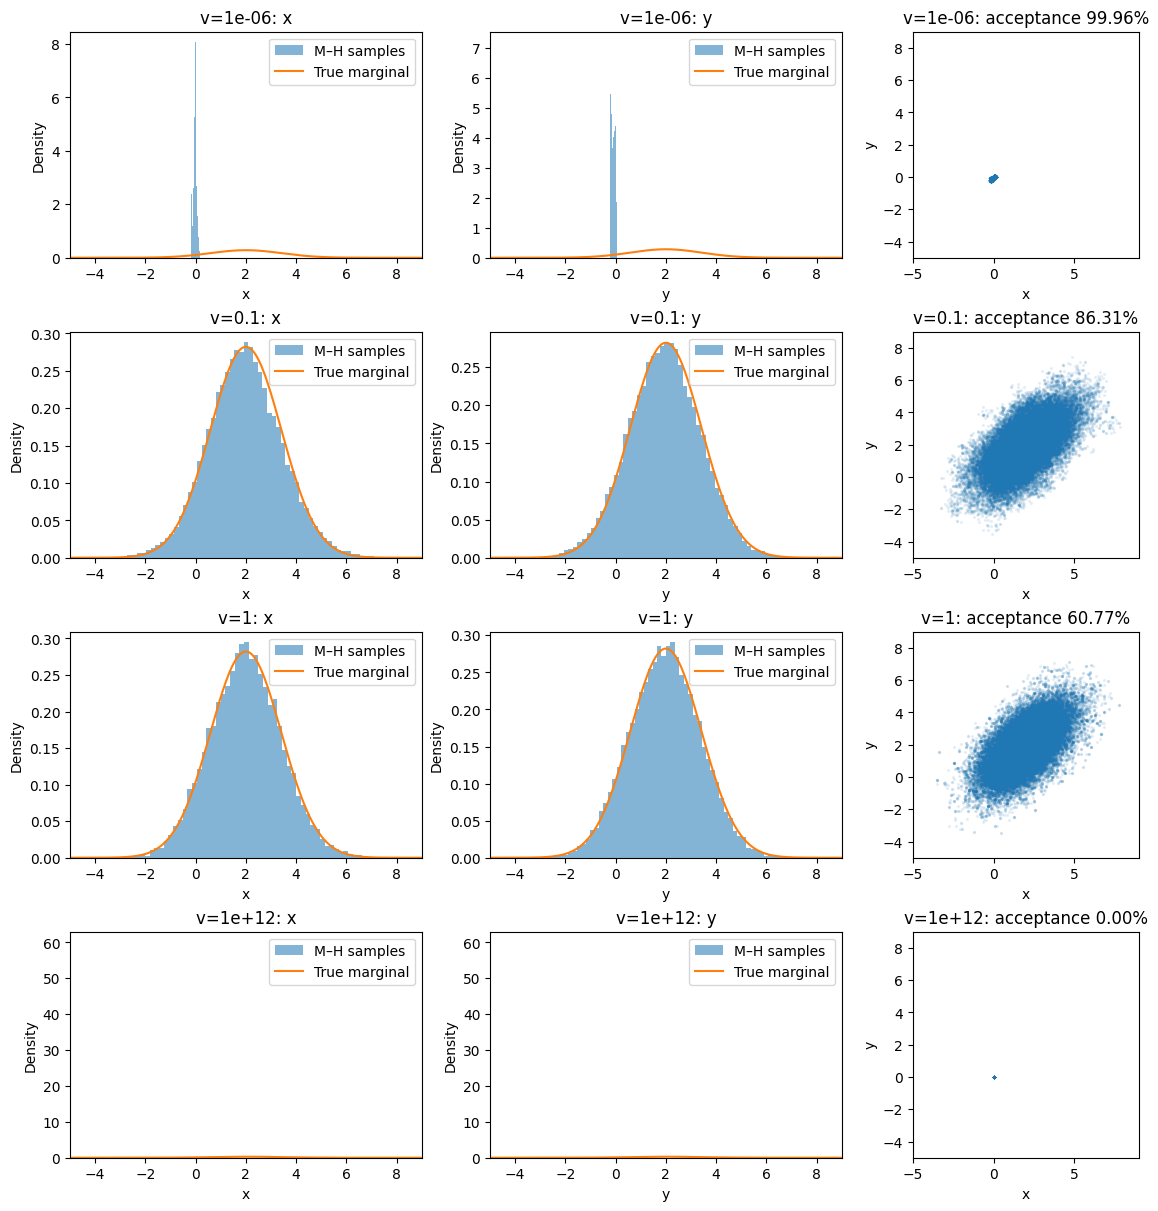

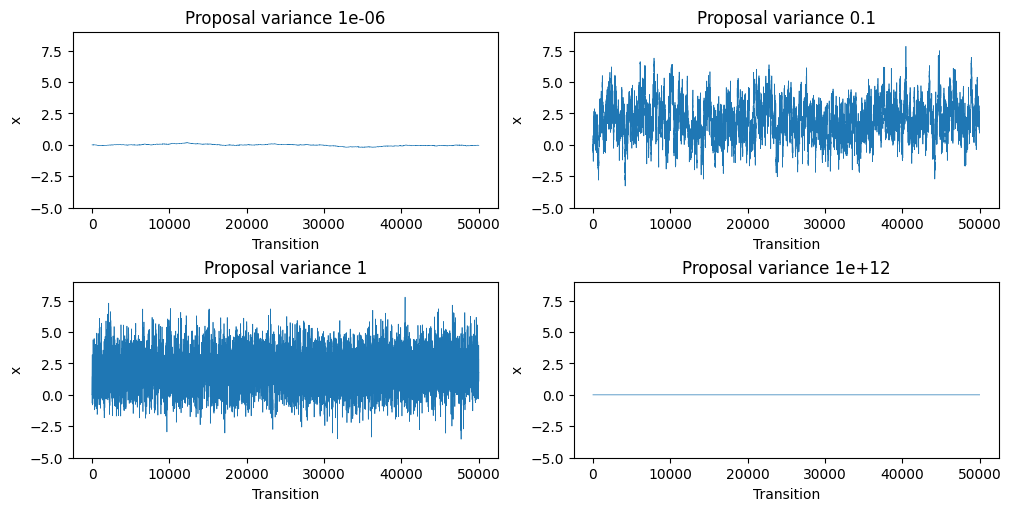

In [2]:
grid = np.linspace(-5, 9, 500)
density = np.exp(-(grid - 2) ** 2 / 4) / np.sqrt(4 * np.pi)
fig, axes = plt.subplots(len(runs), 3, figsize=(12, 12), constrained_layout=True)
for row, (v, chain, acceptance) in enumerate(runs):
    for j, coordinate in enumerate(("x", "y")):
        ax = axes[row, j]
        ax.hist(chain[:, j], bins=60, density=True, alpha=0.55, label="M–H samples")
        ax.plot(grid, density, color="tab:orange", label="True marginal")
        ax.set(title=f"v={v:g}: {coordinate}", xlabel=coordinate, ylabel="Density", xlim=(-5, 9))
        ax.legend()
    ax = axes[row, 2]
    ax.scatter(chain[:, 0], chain[:, 1], s=2, alpha=0.08, rasterized=True)
    ax.set(title=f"v={v:g}: acceptance {acceptance:.2%}", xlabel="x", ylabel="y",
           xlim=(-5, 9), ylim=(-5, 9), aspect="equal")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 5), constrained_layout=True)
for ax, (v, chain, _) in zip(axes.flat, runs):
    ax.plot(chain[:, 0], linewidth=0.5)
    ax.set(xlabel="Transition", ylabel="x", title=f"Proposal variance {v:g}", ylim=(-5, 9))
plt.show()

## What changes at extreme variances?

- **Very small variance ($10^{-6}$):** proposals are almost always accepted, but the chain barely moves. Starting away from the target mean, it cannot explore the target on this run length. High acceptance alone does not imply good sampling.
- **Variance $10^{-1}$:** the proposal standard deviation is about 0.316. This is smaller than the target's marginal standard deviation $\sqrt2$, but is not extremely small here. The chain can explore the target, with more local steps than at variance 1.
- **Variance 1:** gives substantial movement and a moderate acceptance fraction in this example.
- **Variance $10^{12}$:** the proposal standard deviation is one million. Almost every proposal lands enormously far from the target, making the acceptance probability effectively zero. This seeded run stays at its initial state. A histogram spike from a constant chain is not evidence for a narrow target distribution.

Both extremes can give poor exploration over a finite run: small proposals cause slow diffusion, whereas huge proposals cause repeated rejections. The transition rule still targets the same Gaussian mathematically for any positive finite variance; practical sampling quality depends on how much of that distribution the chain explores in the time available. An acceptance fraction and a histogram alone do not establish convergence.